In [1]:
from scrape_rugbypass import *
import pandas as pd
from bs4 import BeautifulSoup
import requests
import datetime
import os

In [2]:
base_url = "https://www.rugbypass.com/live/cardiff-blues-vs-ospreys/?g=942293"

In [3]:
def derive_custom_url(base_url, text):
    prefix, game_number = base_url.split("?")
    return f"{prefix}{text}/?{game_number}"
    
def derive_stats_url(base_url):
    return derive_custom_url(base_url, "stats")

def derive_teams_url(base_url):
    return derive_custom_url(base_url, "teams")

def derive_dirname(base_url):
    prefix, g = base_url.split("?")
    subdirs = [s for s in prefix.split("/") if s != ""]
    return f"{g[2:]}_{subdirs[-1].replace("-", "_")}"

In [4]:
def transform_teams(teams, side):
    return [{'name': name, **info} for name, info in teams[side].items()]

In [5]:
def merge_stats(team, stats):
    rows = []
    for player in team:
        row = player.copy()
        
        for stat, stat_dict in stats.items():
            row[stat] = stat_dict.get(player['name'], 0)
        rows.append(row)
    return rows

def teams_data(match_id, teams, players):
    home = transform_teams(teams, 'home')
    away = transform_teams(teams, 'away')

    away_performances = pd.DataFrame(merge_stats(away, players))
    home_performances = pd.DataFrame(merge_stats(home, players))

    away_performances["home"] = False
    home_performances["home"] = True

    away_performances["match_id"] = match_id
    home_performances["match_id"] = match_id

    return pd.concat([home_performances, away_performances])

In [6]:
def set_percents(name, data, new):
    for c in ["0", "1", "2", "3"]:
        data[f"{name}_{c}"] = new[c]
    return data
    
def separate_side(match, side):
    data = {}
    special = ["territory_percents", "home_poss_percents", "away_poss_percents"]
    
    for k, v in match.items():
        if k == "territory_percents":
            if side == "home":
                data = set_percents("territory_percents", data, v)
            else:
                data = set_percents("territory_percents", data, 
                    {
                        "0": v["3"],
                        "1": v["2"],
                        "2": v["1"],
                        "3": v["0"]
                    })
        elif k == "home_poss_percents":
            if side == "home":
                data = set_percents("poss_percents", data, v)
        elif k == "away_poss_percents":
            if side == "away":
                data = set_percents("poss_percents", data, v)
        else: 
            data[k] = v[side]

    data["home"] = (side == "home") 
    return data
    
def match_data(match_id, competition_id, base, match):
    base["match_id"] = match_id
    base["competition_id"] = competition_id

    side_stats = pd.DataFrame([separate_side(match, "home"), separate_side(match, "away")])
    side_stats["match_id"] = match_id
    
    return base, side_stats

In [7]:
def scrape_all(match_id, competition_id, base_url):
    stats_url = derive_stats_url(base_url)
    teams_url = derive_teams_url(base_url)

    session = requests.Session()

    session.headers.update({
        "User-Agent": "Mozilla/5.0",
        "Origin": "https://www.rugbypass.com",
        "Referer": "https://www.rugbypass.com/",
    })
    
    # scrape base info
    response = session.get(base_url)

    dirname = derive_dirname(base_url)
    os.makedirs(f"rugbypass/{dirname}", exist_ok=True)
    
    with open(f"rugbypass/{dirname}/base.html", "w") as f:
        f.write(response.text)
     
    base_data = process_base(response, competition_id)

    # scrape match stats
    response = session.get(stats_url)
    with open(f"rugbypass/{dirname}/stats.html", "w") as f:
        f.write(response.text)
     
    match_stats = process_match_stats(response)
    
    # scrape player stats
    player_stats = scrape_stats(session, stats_url)

    # scrape teams
    teams = scrape_teams(session, teams_url)

    base, side_stats = match_data(match_id, competition_id, base_data, match_stats)
    performances = teams_data(match_id, teams, player_stats)

    return base, side_stats, performances

In [8]:
base, side_stats, performances = scrape_all(1234, 0, base_url)

In [9]:
base

{'home_team': 'Cardiff Rugby',
 'away_team': 'Ospreys',
 'date': datetime.date(2025, 1, 1),
 'competition_id': 0,
 'extra_info': 'Round 9',
 'match_id': 1234}

In [10]:
side_stats

,penalty_goals,tries,conversions,drop_goals,carries,line_breaks,turnovers_lost,turnovers_won,territory,possession_last_10_min,...,territory_percents_0,territory_percents_1,territory_percents_2,territory_percents_3,poss_percents_0,poss_percents_1,poss_percents_2,poss_percents_3,home,match_id
0,1,2,0,0,96,0,11,10,0.41,0.4,...,0.10,0.45,0.21,0.24,0.12,0.31,0.30,0.27,True,1234
1,2,1,1,0,104,3,15,6,0.59,0.6,...,0.24,0.21,0.45,0.10,0.10,0.21,0.57,0.12,False,1234


In [11]:
from tqdm import tqdm

def scrape_urls(urls):
    base_rows = []
    side_rows = []
    perf_rows = []

    for match_id, row in tqdm(urls.iterrows()):
        base, side_stats, perfs = scrape_all(match_id, row["competition_id"], row["url"])

        base_rows.append(base)
        side_rows.append(side_stats)
        perf_rows.append(perfs)

    return base_rows, side_rows, perf_rows

In [12]:
urls = pd.read_parquet("all_urls.parquet")

In [13]:
base_rows, side_rows, perf_rows = scrape_urls(urls)

1573it [1:29:47,  3.42s/it]


In [17]:
base_data = pd.DataFrame(base_rows)
base_data.set_index("match_id", inplace=True)

In [27]:
base_data.to_parquet("rugbypass_base_data.parquet")

In [21]:
side_data = pd.concat(side_rows, ignore_index=True)

In [26]:
side_data.to_parquet("rugbypass_side_data.parquet")

In [23]:
perf_data = pd.concat(perf_rows, ignore_index=True)

In [25]:
perf_data.to_parquet("rugbypass_perf_data.parquet")

In [33]:
import seaborn as sns

In [36]:
fh = perf_data[perf_data["number"] == 9.0].groupby("name").apply(lambda p: p["passes"].mean())

<Axes: ylabel='Count'>

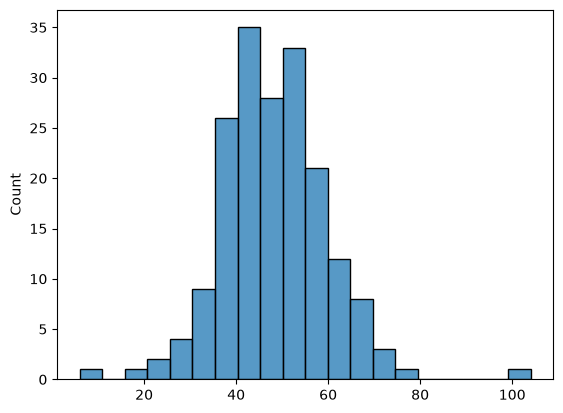

In [37]:
sns.histplot(fh)

In [42]:
fh.sort_values()

name
Matthew Devine           6.000000
Jonathan Pelissie       19.500000
Dave Shanahan           22.000000
Julien Blanc            25.500000
Hugo Gomes Camacho      26.000000
                          ...    
Max Green               70.000000
Jamison Gibson-Park     72.508475
Luke Davies             73.000000
Ben Afshar              75.500000
Ratko Jelic            104.000000
Length: 185, dtype: float64

In [43]:
perf_data[perf_data["name"] == "Ratko Jelic"]

,name,number,minutes_played,carries,clean_breaks,completed_tackles,turnovers_conceded,turnovers_won,total_kicks,passes,...,missed_tackles,dominant_tackles,ruck_turnovers,lineouts_won,tackles_per_minute,red_cards,yellow_cards,penalties_conceded,home,match_id
5701,Ratko Jelic,21.0,28.0,1.0,0.0,3.0,0.0,0.0,3.0,19.0,...,2.0,1.0,0.0,0.0,0.19,0.0,0.0,0.0,False,932950
5977,Ratko Jelic,21.0,16.0,2.0,0.0,1.0,1.0,0.0,1.0,7.0,...,0.0,0.0,0.0,0.0,0.06,0.0,0.0,0.0,False,932962
6851,Ratko Jelic,21.0,40.0,5.0,0.0,3.0,1.0,0.0,4.0,39.0,...,1.0,1.0,0.0,0.0,0.10,0.0,0.0,0.0,False,932974
7058,Ratko Jelic,21.0,13.0,1.0,0.0,0.0,0.0,0.0,3.0,13.0,...,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,True,932982
7541,Ratko Jelic,21.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,False,932994
8070,Ratko Jelic,21.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,True,932996
8300,Ratko Jelic,21.0,15.0,0.0,0.0,0.0,1.0,0.0,0.0,19.0,...,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,True,933005
8691,Ratko Jelic,21.0,54.0,3.0,0.0,4.0,1.0,0.0,6.0,58.0,...,3.0,1.0,0.0,0.0,0.13,0.0,0.0,0.0,False,933012
13463,Ratko Jelic,9.0,71.0,1.0,0.0,5.0,2.0,0.0,8.0,104.0,...,2.0,0.0,0.0,0.0,0.10,0.0,0.0,1.0,False,942226


In [61]:
perf_data.columns

Index(['name', 'number', 'minutes_played', 'carries', 'clean_breaks',
       'completed_tackles', 'turnovers_conceded', 'turnovers_won',
       'total_kicks', 'passes', 'carries_metres', 'offloads',
       'defenders_beaten', 'try_assists', 'tries', 'carries_per_minute',
       'total_tackles', 'missed_tackles', 'dominant_tackles', 'ruck_turnovers',
       'lineouts_won', 'tackles_per_minute', 'red_cards', 'yellow_cards',
       'penalties_conceded', 'home', 'match_id'],
      dtype='str')

In [72]:
def score_common(player): 
    #+ 2 * player['conversions'] \
    #+ 3 * player['penalties_kicked'] \
    #+ 5 * player['drop_goals'] \
    #+ 7 * player['lineout_steals'] \
    return 10 * player['tries'] \
        + 4 * player['try_assists'] \
        + 2 * player['defenders_beaten'] \
        + player['carries_metres'] // 10 \
        + player['completed_tackles'] \
        + 5 * player['turnovers_won'] \
        + 2 * player['offloads'] \
        - 5 * player['yellow_cards'] \
        - 8 * player['red_cards']

In [73]:
perf_data["score"] = score_common(perf_data)

In [77]:
nonzero_perfs = perf_data[perf_data["minutes_played"] > 0]
nonzero_perfs["score_per_minute"] = nonzero_perfs["score"] / nonzero_perfs["minutes_played"]

In [109]:
base_data.loc[nonzero_perfs["match_id"]]

,home_team,away_team,date,competition_id,extra_info
match_id,,,,,
921086,Ireland,Wales,2022-02-05,0,Round 1
921086,Ireland,Wales,2022-02-05,0,Round 1
921086,Ireland,Wales,2022-02-05,0,Round 1
921086,Ireland,Wales,2022-02-05,0,Round 1
921086,Ireland,Wales,2022-02-05,0,Round 1
...,...,...,...,...,...
948487,Leinster,Bordeaux,2026-05-23,4,Final
948487,Leinster,Bordeaux,2026-05-23,4,Final
948487,Leinster,Bordeaux,2026-05-23,4,Final


<Axes: xlabel='score_per_minute', ylabel='Count'>

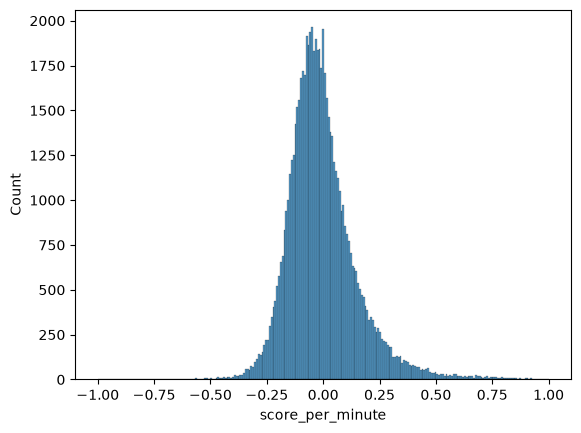

In [120]:
df = nonzero_perfs.join(base_data, on="match_id")
#df = df[df["competition_id"] == 2]

player_averages = df.groupby("name").apply(lambda p: p["score_per_minute"].mean())
difference_from_avg = df["score_per_minute"] - player_averages[df["name"]].values
sns.histplot(difference_from_avg, binrange=(-1, 1))

<Axes: xlabel='score', ylabel='Count'>

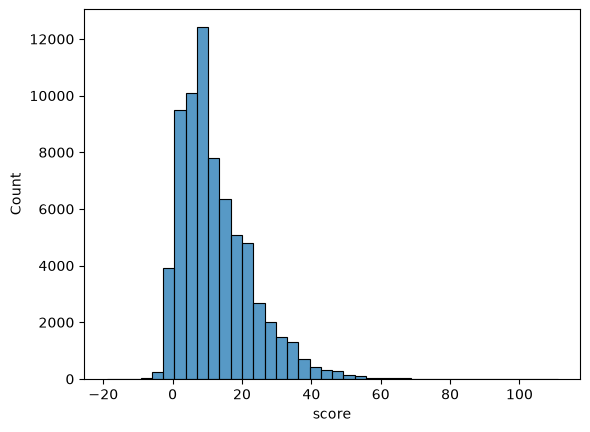

In [117]:
sns.histplot(perf_data["score"], bins=40)

In [126]:
from scipy.stats import norm, lognorm

s, loc, scale = lognorm.fit(nonzero_perfs["score_per_minute"])


<Axes: ylabel='Count'>

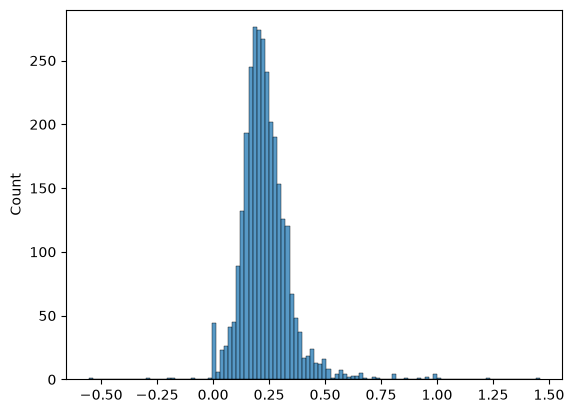

In [122]:
sns.histplot(nonzero_perfs.groupby("name").apply(lambda p: p["score_per_minute"].mean()))

In [129]:
sns.plot(lambda x: lognorm.pdf(x, s, loc=loc, scale=scale))

AttributeError: module 'seaborn' has no attribute 'plot'